<a href="https://colab.research.google.com/github/krishnaani2004-cloud/intermediate_assesment/blob/main/Intermediate_Assessment_II_HR_Analytics_krishna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intermediate Assessment II – HR Analytics




In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import f1_score, accuracy_score, classification_report, roc_auc_score

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")


## 2. Upload the Three Files



In [4]:


TRAIN_FILE = "/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/train_LZdllcl.csv"
TEST_FILE = "/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/test_2umaH9m.csv"
SAMPLE_FILE = "/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/sample_submission_M0L0uXE.csv"

train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
sample = pd.read_csv(SAMPLE_FILE)

print("\nTrain shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample.shape)



Train shape: (54808, 14)
Test shape: (23490, 13)
Sample submission shape: (23490, 2)


## 3. Understand the Data

In [5]:
print("Train columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

print("\nFirst 5 rows of train data:")
display(train.head())

print("\nFirst 5 rows of test data:")
display(test.head())


Train columns:
['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score', 'is_promoted']

Test columns:
['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score']

First 5 rows of train data:


,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0



First 5 rows of test data:


,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,8724,Technology,region_26,Bachelor's,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelor's,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelor's,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelor's,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelor's,m,sourcing,1,30,4.0,7,0,0,61


In [6]:
print("Train data types:")
display(train.dtypes)

print("\nMissing values in train:")
display(train.isnull().sum())

print("\nMissing values in test:")
display(test.isnull().sum())


Train data types:


,0
employee_id,int64
department,object
region,object
education,object
gender,object
recruitment_channel,object
no_of_trainings,int64
age,int64
previous_year_rating,float64
length_of_service,int64



Missing values in train:


,0
employee_id,0
department,0
region,0
education,2409
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,4124
length_of_service,0



Missing values in test:


,0
employee_id,0
department,0
region,0
education,1034
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,1812
length_of_service,0


## 4. Exploratory Data Analysis (EDA)



Target distribution:


,count
is_promoted,
0,50140
1,4668



Target percentage:


,proportion
is_promoted,
0,91.482995
1,8.517005


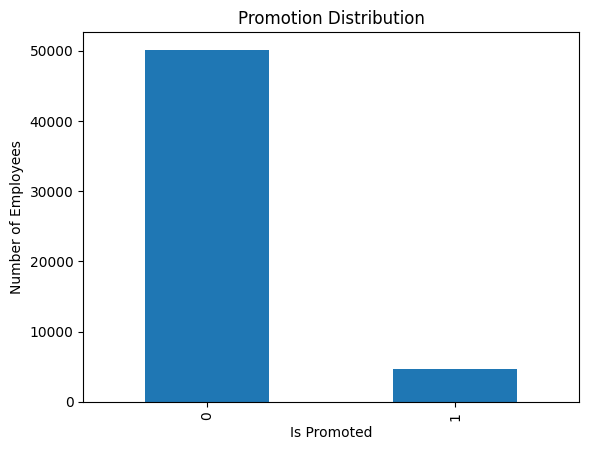

In [7]:
print("Target distribution:")
display(train["is_promoted"].value_counts())

print("\nTarget percentage:")
display(train["is_promoted"].value_counts(normalize=True) * 100)

train["is_promoted"].value_counts().plot(kind="bar")
plt.title("Promotion Distribution")
plt.xlabel("Is Promoted")
plt.ylabel("Number of Employees")
plt.show()


In [8]:
# Numerical summary
display(train.describe())


,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


In [9]:
display(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


None

,is_promoted
department,
Technology,0.107593
Procurement,0.096386
Analytics,0.095665
Operations,0.090148
Finance,0.081230
Sales & Marketing,0.072031
R&D,0.069069
HR,0.056245
Legal,0.051011


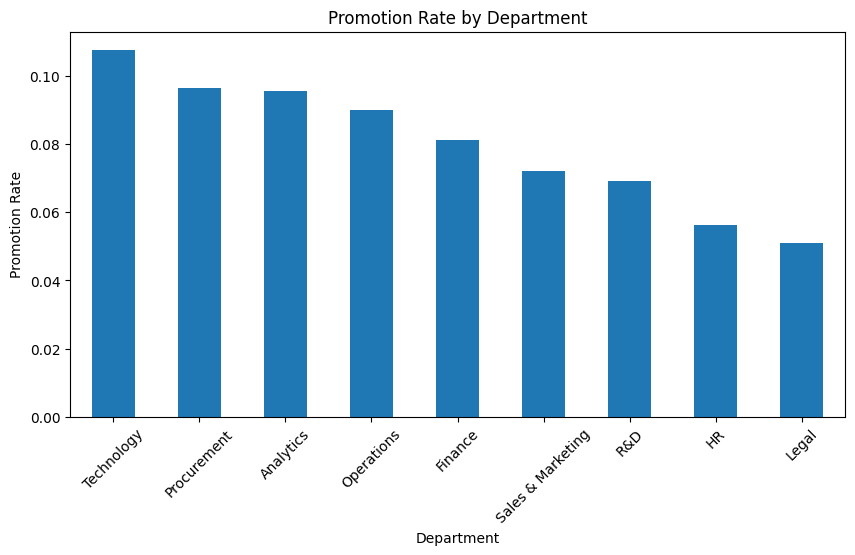

In [10]:
# Promotion rate by department
promotion_by_department = train.groupby("department")["is_promoted"].mean().sort_values(ascending=False)
display(promotion_by_department)

promotion_by_department.plot(kind="bar", figsize=(10, 5))
plt.title("Promotion Rate by Department")
plt.xlabel("Department")
plt.ylabel("Promotion Rate")
plt.xticks(rotation=45)
plt.show()


,is_promoted
previous_year_rating,
1.0,0.014141
2.0,0.042840
3.0,0.072779
4.0,0.079376
5.0,0.163615


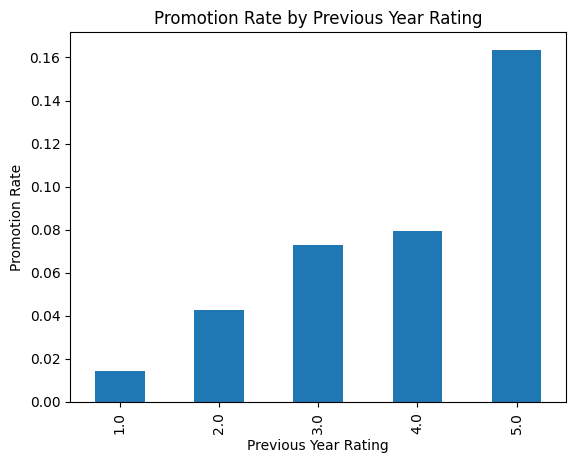

In [11]:
# Promotion rate by previous year rating
promotion_by_rating = train.groupby("previous_year_rating")["is_promoted"].mean()
display(promotion_by_rating)

promotion_by_rating.plot(kind="bar")
plt.title("Promotion Rate by Previous Year Rating")
plt.xlabel("Previous Year Rating")
plt.ylabel("Promotion Rate")
plt.show()


## 5. Prepare Features



In [12]:
# Separate target from training features
X = train.drop(columns=["is_promoted"]).copy()
y = train["is_promoted"].copy()

# Keep employee_id for the final submission, but do not use it for prediction
test_ids = test["employee_id"].copy()

# Remove only the identifier column from model features
X = X.drop(columns=["employee_id"])
X_test = test.drop(columns=["employee_id"]).copy()

print("X shape:", X.shape)
print("X_test shape:", X_test.shape)
print("y shape:", y.shape)


X shape: (54808, 12)
X_test shape: (23490, 12)
y shape: (54808,)


In [13]:
# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)


Categorical columns:
['department', 'region', 'education', 'gender', 'recruitment_channel']

Numerical columns:
['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met >80%', 'awards_won?', 'avg_training_score']


## 6. Train/Validation Split

A stratified split is used because the promotion class is much smaller than the non-promotion class.


In [14]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

print("\nTraining target distribution:")
display(y_train.value_counts())


Training rows: 43846
Validation rows: 10962

Training target distribution:


,count
is_promoted,
0,40112
1,3734


## 7. Pre-processing

- Numerical missing values → median
- Categorical missing values → most frequent value
- Categorical variables → One-Hot Encoding
- Unknown categories in validation/test → ignored

The preprocessing is fitted only on `X_train`. It is not fitted on the combined train + test data.


In [15]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])


## 8. Baseline Model




In [16]:
baseline_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", baseline_model)
])

baseline_pipeline.fit(X_train, y_train)

valid_probability = baseline_pipeline.predict_proba(X_valid)[:, 1]
baseline_prediction = (valid_probability >= 0.50).astype(int)

print("Baseline Accuracy:", accuracy_score(y_valid, baseline_prediction))
print("Baseline F1 Score:", f1_score(y_valid, baseline_prediction))
print("Baseline ROC-AUC:", roc_auc_score(y_valid, valid_probability))

print("\nClassification Report:")
print(classification_report(y_valid, baseline_prediction))


Baseline Accuracy: 0.9426199598613392
Baseline F1 Score: 0.49880478087649405
Baseline ROC-AUC: 0.9115670982063926

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     10028
           1       0.98      0.34      0.50       934

    accuracy                           0.94     10962
   macro avg       0.96      0.67      0.73     10962
weighted avg       0.94      0.94      0.93     10962



## 9. Fine Tuning the Model

Instead of using a very complicated search, we make a stronger XGBoost model by adjusting a few important parameters.

We will also tune the **classification threshold** on the validation set because the assessment problem is imbalanced and the competition commonly evaluates the promotion class using F1 score.


In [17]:
tuned_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=2,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

tuned_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", tuned_model)
])

tuned_pipeline.fit(X_train, y_train)

valid_probability = tuned_pipeline.predict_proba(X_valid)[:, 1]

print("ROC-AUC:", roc_auc_score(y_valid, valid_probability))


ROC-AUC: 0.9108184449707842


In [18]:
# Find a practical threshold using only the validation data
thresholds = np.arange(0.20, 0.81, 0.01)

best_threshold = 0.50
best_f1 = 0

for threshold in thresholds:
    prediction = (valid_probability >= threshold).astype(int)
    score = f1_score(y_valid, prediction)

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best validation threshold:", round(best_threshold, 2))
print("Best validation F1:", round(best_f1, 4))

final_valid_prediction = (valid_probability >= best_threshold).astype(int)

print("\nAccuracy:", round(accuracy_score(y_valid, final_valid_prediction), 4))
print("F1 Score:", round(f1_score(y_valid, final_valid_prediction), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, valid_probability), 4))

print("\nClassification Report:")
print(classification_report(y_valid, final_valid_prediction))


Best validation threshold: 0.29
Best validation F1: 0.5374

Accuracy: 0.9356
F1 Score: 0.5374
ROC-AUC: 0.9108

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97     10028
           1       0.69      0.44      0.54       934

    accuracy                           0.94     10962
   macro avg       0.82      0.71      0.75     10962
weighted avg       0.93      0.94      0.93     10962



## 10. Train the Final Model on All Training Data




In [19]:
final_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=2,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_model)
])

# Fit only on the original training data
final_pipeline.fit(X, y)

print("Final model trained successfully.")


Final model trained successfully.


## 11. Predict the Test Data

The same fitted preprocessing steps are applied to the test data.

No rows are removed from the test dataset.


In [20]:
test_probability = final_pipeline.predict_proba(X_test)[:, 1]

test_prediction = (test_probability >= best_threshold).astype(int)

print("Number of test predictions:", len(test_prediction))
print("\nPrediction distribution:")
display(pd.Series(test_prediction).value_counts())

print("\nFirst 10 predictions:")
print(test_prediction[:10])


Number of test predictions: 23490

Prediction distribution:


,count
0,22338
1,1152



First 10 predictions:
[0 0 0 0 0 0 0 0 0 1]


## 12. Create the Submission File




In [21]:
# Check that the IDs are in the same order
assert len(sample) == len(test)
assert sample["employee_id"].equals(test["employee_id"])

submission = sample.copy()
submission["is_promoted"] = test_prediction

print("Submission shape:", submission.shape)
display(submission.head())

print("\nSubmission target distribution:")
display(submission["is_promoted"].value_counts())

submission.to_csv("/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/submission_xgb.csv", index=False)

print("\nSaved as: submission_xgb.csv")


Submission shape: (23490, 2)


,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0



Submission target distribution:


,count
is_promoted,
0,22338
1,1152



Saved as: submission_xgb.csv


In [23]:
# Download the final submission file
files.download("/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/submission_xgb.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# Example: create another submission with threshold 0.50
alternative_threshold = 0.50

alternative_prediction = (test_probability >= alternative_threshold).astype(int)

alternative_submission = sample.copy()
alternative_submission["is_promoted"] = alternative_prediction

alternative_submission.to_csv("/content/drive/MyDrive/DSAB11/feature_engineering andvisualization/intermediate assesmnt/submission_threshold_050.csv", index=False)

print("Alternative file saved as submission_threshold_050.csv")


Alternative file saved as submission_threshold_050.csv


## Final Notes

- `employee_id` was excluded from modeling because it is an identifier, not a meaningful feature.
- No rows were deleted.
- Missing values were imputed.
- Train and test data were not combined.
- The validation set was used only to compare/tune the model and select the classification threshold.
- The final model was retrained using all available training rows.
- The provided sample submission format was preserved.
- Upload `submission_xgb.csv` to Analytics Vidhya and record the score.
